# SEM visco-elastic attenuation in 3-D

`ViscoElasticVSSEM3D` (Hex8) and `ViscoElasticVSSEM3DDeformed` (Hex27, under a topography) put
the generalized standard linear solid of `ViscoElasticVSSEM2DDeformed` -- SPECFEM's rheology, and
the FD `ViscoElastic`'s -- on the 3-D velocity-stress SEM: six memory variables per mechanism,
the models `vp, vs, rho, Qp, Qs`, and the C-PML of the velocity-stress classes, so that
attenuation, a topography and absorbing boundaries work together in 3-D.

1. A point force in a whole space against the visco-elastic Green's function.
2. A force under a hill: the surface records with and without attenuation.

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations.visco_elastic import (GSLSFit, gsls_band, gsls_moduli_factors,
                                           gsls_relaxation_times)
from sweep.propagator import EagerOptions, Full
from sweep.sem import (ElasticVSSEM3D, ElasticVSSEM3DDeformed, PropSEM, ViscoElasticVSSEM3D,
                       ViscoElasticVSSEM3DDeformed)

DEV = "cuda" if torch.cuda.is_available() else "cpu"   # the visco classes run on impl='eager'
F64 = torch.float64
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
print(f"device {DEV}")

device cuda


## 1. A point force against the visco-elastic Green's function

In a homogeneous whole space the visco-elastic response is the elastic one with complex,
frequency-dependent velocities (the correspondence principle). For a point force that is Aki &
Richards' (4.23), near field included, evaluated in the frequency domain with the P and shear
moduli the class fits,

    M(w) = M_R (1 + sum_l t_l i w tau_l / (1 + i w tau_l)),

`tau_l` the relaxation times over the band and `t_l` the strengths for the model's Q. The SEM
run has a C-PML on all six sides, a vertical force at the centre of a 320 m cube and six
receivers 60 to 113 m from it, in several directions; the GLL spacing is 5 m.

In [2]:
DH, NO, F0, DELAY = 5.0, 4, 12.0, 0.1
SHAPE, ABCN, DT, NT = (65, 65, 65), 24, 4e-4, 900        # a 320 m cube, 0.36 s
VP, VS, RHO, QP, QS = 2000.0, 1000.0, 2000.0, 25.0, 15.0
F_REF, N_SLS = 10.0, 3                                    # the class's defaults
src = np.array([[32.0, 32.0, 32.0]])                      # (ix, iy, iz) grid indices
offs = np.array([(12, 0, 0), (0, 0, 12), (8, 8, 8), (-16, 4, 6), (4, -10, -14), (0, 16, 16)],
                dtype=float)
rec = (src + offs)[None]
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - DELAY)) ** 2
wav = (1 - 2 * a) * np.exp(-a)


def run(eq, extra=()):
    p = PropSEM(eq, shape=SHAPE, dh=DH, dt=DT, n_order=NO, abcn=ABCN, free_surface=False,
                f_dominant=F0, dev=DEV, dtype=F64, impl="eager", memory=Full(),
                eager_options=EagerOptions(use_compile=False), source_type=["vz"],
                receiver_type=["vz"])
    ms = [torch.full(SHAPE, v, dtype=F64, device=DEV) for v in (VP, VS, RHO) + tuple(extra)]
    t0 = time.time()
    with torch.no_grad():
        out = p(torch.from_numpy(wav).to(DEV), src, rec, models=ms)[0, :, :, 0].cpu().numpy()
    print(f"{eq.__name__}: {time.time() - t0:.1f} s")
    return out


visco = run(ViscoElasticVSSEM3D, (QP, QS))
elastic = run(ElasticVSSEM3D)

ViscoElasticVSSEM3D: 48.7 s


ElasticVSSEM3D: 42.8 s


In [3]:
# the moduli the class fits: relaxation times over the band, strengths for each Q, and the
# relaxed moduli from the phase velocities at F_REF
band = gsls_band(F_REF, None)
tau = gsls_relaxation_times(N_SLS, *band)
fit = GSLSFit(tau, *band, n_freq=200)
NF = 8 * NT
om = 2 * np.pi * np.fft.rfftfreq(NF, DT)


def modulus(v, q):
    t_l = list(fit.tau(torch.tensor(q, dtype=F64)))       # one strength per mechanism
    _, s_R = gsls_moduli_factors(t_l, tau, F_REF)
    M_R = RHO * v * v * float(s_R)
    return M_R * (1 + sum(float(c) * 1j * om * s / (1 + 1j * om * s) for c, s in zip(t_l, tau)))


def greens_vz(pi_w, mu_w, x):
    """vz at x (m) of the vertical force `wav` at the origin, sampled at (n + 1/2) dt like
    the velocity-stress records."""
    r = np.linalg.norm(x)
    gzz = (x[2] / r) ** 2
    al, be = np.sqrt(pi_w / RHO), np.sqrt(mu_w / RHO)
    ta, tb = r / al, r / be
    with np.errstate(divide="ignore", invalid="ignore"):
        prim = lambda s: np.exp(-1j * om * s) * (1 + 1j * om * s) / om ** 2
        near = prim(tb) - prim(ta)
    near[0] = 0.5 * (tb[0] ** 2 - ta[0] ** 2)
    uz = np.fft.rfft(wav, NF) / (4 * np.pi * RHO) * (
        (3 * gzz - 1) / r ** 3 * near + gzz / (al ** 2 * r) * np.exp(-1j * om * ta)
        - (gzz - 1) / (be ** 2 * r) * np.exp(-1j * om * tb))
    return np.fft.irfft(1j * om * uz * np.exp(0.5j * om * DT), NF)[:NT]


pi_w, mu_w = modulus(VP, QP), modulus(VS, QS)
el_w = lambda v: np.full(om.shape, RHO * v * v, dtype=complex)
ana_v = np.stack([greens_vz(pi_w, mu_w, DH * d) for d in offs], 1)
ana_e = np.stack([greens_vz(el_w(VP), el_w(VS), DH * d) for d in offs], 1)
rel = lambda x, y: np.linalg.norm(x - y, axis=0) / np.linalg.norm(y, axis=0)
dist = DH * np.linalg.norm(offs, axis=1)
print("distance (m)                 ", np.round(dist, 1))
sci = lambda x: "  ".join(f"{v:.1e}" for v in x)
print("SEM visco vs its solution    ", sci(rel(visco, ana_v)))
print("visco vs elastic solution    ", sci(rel(ana_e, ana_v)))
print("SEM elastic vs its solution  ", sci(rel(elastic, ana_e)))

distance (m)                  [ 60.   60.   69.3  87.7  88.3 113.1]
SEM visco vs its solution     8.9e-04  7.3e-04  7.9e-04  1.0e-03  1.2e-03  9.8e-04
visco vs elastic solution     2.5e-01  1.2e-01  3.0e-01  3.6e-01  3.9e-01  4.7e-01
SEM elastic vs its solution   1.4e-03  1.7e-03  1.4e-03  1.5e-03  1.5e-03  1.2e-03


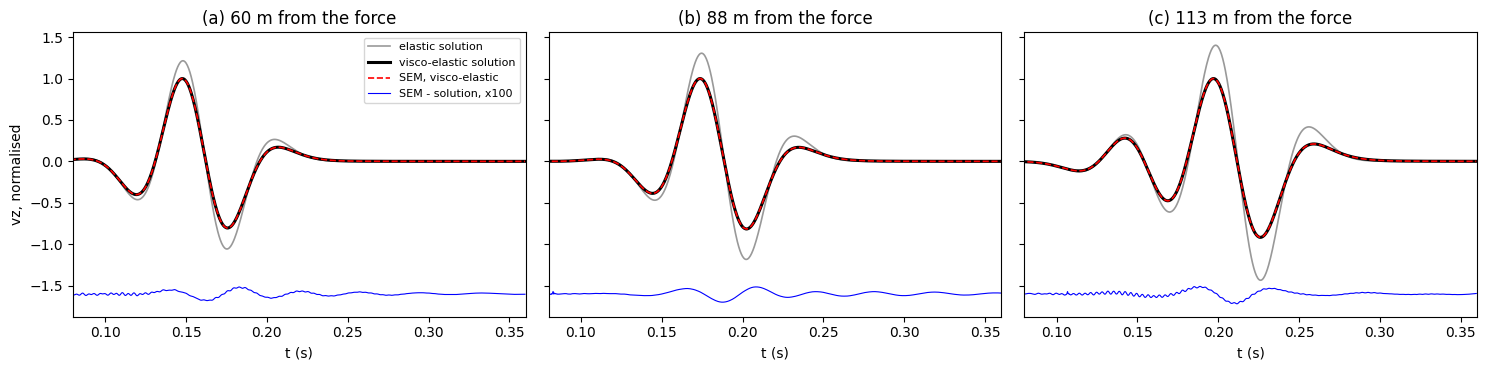

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, k, lab in zip(ax, (0, 3, 5), "abc"):
    s = 1.0 / np.abs(ana_v[:, k]).max()
    a_.plot(t, s * ana_e[:, k], color="0.6", lw=1.2, label="elastic solution")
    a_.plot(t, s * ana_v[:, k], "k", lw=2.2, label="visco-elastic solution")
    a_.plot(t, s * visco[:, k], "r--", lw=1.2, label="SEM, visco-elastic")
    a_.plot(t, 100 * s * (visco[:, k] - ana_v[:, k]) - 1.6, "b", lw=0.8,
            label="SEM - solution, x100")
    a_.set_title(f"({lab}) {dist[k]:.0f} m from the force")
    a_.set_xlabel("t (s)")
    a_.set_xlim(0.08, 0.36)
ax[0].set_ylabel("vz, normalised")
ax[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

The SEM record follows the visco-elastic solution to about 1e-3 in relative L2 at every
receiver (the residual is drawn a hundred times larger), while the attenuation changes the
records by 12% to 47%: the attenuated pulse is smaller and slightly broader, and arrives at
nearly the same time, since `vp` and `vs` are the phase velocities at `F_REF` = 10 Hz, close to
the source's 12 Hz. The elastic class has the same error against its own solution on this
grid, so what is left is the discretisation and the C-PML's echo, not the attenuation.
`test/sem/test_sem_visco_elastic3d.py` runs a coarser version of this check.

## 2. A force under a hill

`ViscoElasticVSSEM3DDeformed` follows a topography with its Hex27 mesh; the top is free and the
other five sides absorb. A vertical force 50 m under the foot of a 60 m hill, receivers along
the surface over the hill, and the same run with `Q = inf` replaced by `Qp = 30`, `Qs = 20`
(`vp`, `vs` are the phase velocities at `F_REF`, so both runs keep the same speeds there).

In [5]:
DH2, DT2, NT2 = 10.0, 5e-4, 1600                           # 0.8 s
SHAPE2, ABCN2 = (41, 61, 101), 16                          # 400 x 600 x 1000 m
ny, nx = SHAPE2[1], SHAPE2[2]
yy, xx = np.meshgrid(np.arange(ny), np.arange(nx), indexing="ij")
topo = 6.0 - 6.0 * np.exp(-((xx - 60) ** 2 + (yy - 30) ** 2) / (2 * 12.0 ** 2))  # rows
t2 = np.arange(NT2) * DT2
a2 = (np.pi * F0 * (t2 - DELAY)) ** 2
wav2 = torch.from_numpy((1 - 2 * a2) * np.exp(-a2)).to(DEV)
src2 = np.array([[25.0, 30.0, topo[30, 25] + 5.0]])
rx = np.arange(10.0, 86.0, 1.0)                           # 150 m off the C-PML
rec2 = np.stack([rx, np.full_like(rx, 30.0), topo[30, rx.astype(int)]], 1)[None]


def run2(eq, extra=()):
    p = PropSEM(eq, shape=SHAPE2, dh=DH2, dt=DT2, n_order=NO, abcn=ABCN2, topography=topo,
                free_surface=True, f_dominant=F0, dev=DEV, dtype=F64, impl="eager",
                memory=Full(), eager_options=EagerOptions(use_compile=False),
                source_type=["vz"], receiver_type=["vz"])
    ms = [torch.full(SHAPE2, v, dtype=F64, device=DEV) for v in (VP, VS, RHO) + tuple(extra)]
    t0 = time.time()
    with torch.no_grad():
        out = p(wav2, src2, rec2, models=ms)[0, :, :, 0].cpu().numpy()
    print(f"{eq.__name__}: {time.time() - t0:.1f} s")
    return out


hill_el = run2(ElasticVSSEM3DDeformed)
hill_vi = run2(ViscoElasticVSSEM3DDeformed, (30.0, 20.0))

ElasticVSSEM3DDeformed: 70.9 s


ViscoElasticVSSEM3DDeformed: 77.2 s


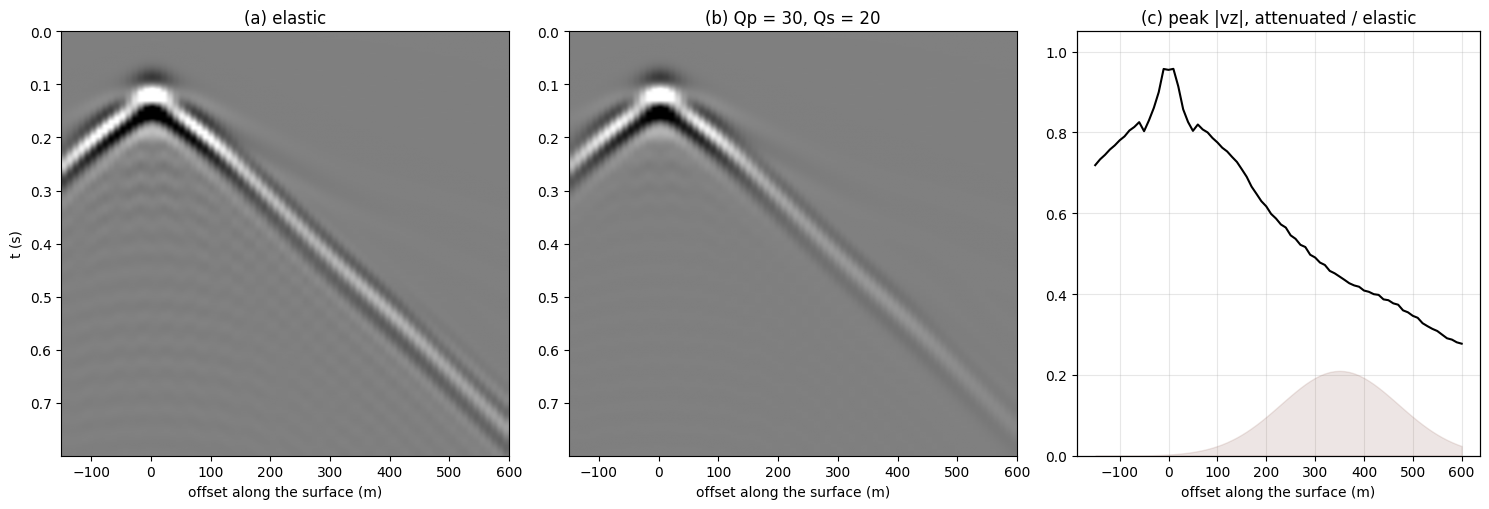

In [6]:
fig = plt.figure(figsize=(15, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.9])
clip = np.percentile(np.abs(hill_el), 99.5)
off = (rx - src2[0, 0]) * DH2
for i, (data, lab) in enumerate(((hill_el, "(a) elastic"), (hill_vi, "(b) Qp = 30, Qs = 20"))):
    a_ = fig.add_subplot(gs[i])
    a_.imshow(data, aspect="auto", cmap="gray", vmin=-clip, vmax=clip,
              extent=[off[0], off[-1], t2[-1], t2[0]])
    a_.set_title(lab)
    a_.set_xlabel("offset along the surface (m)")
    if i == 0:
        a_.set_ylabel("t (s)")
a_ = fig.add_subplot(gs[2])
ratio = np.abs(hill_vi).max(0) / np.abs(hill_el).max(0)
a_.plot(off, ratio, "k")
a_.set_title("(c) peak |vz|, attenuated / elastic")
a_.set_xlabel("offset along the surface (m)")
a_.set_ylim(0.0, 1.05)
a_.grid(alpha=0.3)
ax2 = a_.twinx()
ax2.fill_between(off, 0, -topo[30, rx.astype(int)] * DH2 + 60, color="tab:brown", alpha=0.15)
ax2.set_ylim(0, 300)
ax2.set_yticks([])
fig.tight_layout()
plt.show()

The attenuated section (b) keeps the elastic one's arrivals, over the hill as elsewhere, with
amplitudes that fall faster with distance: the ratio of the peak amplitudes (c) is about 0.95
next to the source and about 0.3 at 600 m. The hill's profile is shaded behind (c).

---

<p><strong>Download this notebook</strong> &mdash; <a href="59_sem_visco_elastic3d.ipynb" download><code>59_sem_visco_elastic3d.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/59_sem_visco_elastic3d.ipynb">view on GitHub</a></p>